# LiquidAI/d1-3B — Google Colab 推論デモ

**画像 + テキスト → Yes/No・選択肢分類・段階スコア**を試します。対象： [LiquidAI/d1-3B](https://huggingface.co/LiquidAI/d1-3B) | [公式ドキュメント](https://huggingface.co/LiquidAI/d1-3B#how-to-use)

## 実行方法
1. Colab の **ランタイム → ランタイムのタイプを変更 → T4 GPU**（または L4 / A100）を選択。
2. ノートブックを**上から順に実行**。デモ写真は埋め込まれているのでアップロード不要。
3. 実際に自分の画像で試す場合は、最後の「任意の画像アップロード」セルを実行。

公式推論 API は `model.system_one(state, questions, images=[image])`。**文章を生成するモデルではありません**。
複数の質問に対して、`noul` (Yes/No)、`choice` (択一)、`score` (順序尺度) を返します。

> 注意：初回起動時に **約6.25 GB のモデル重み**をダウンロードします。`trust_remote_code=True` でモデル作者のコードが実行されます。公開モデルのコードを確認したうえで実行してください。Colab の GPU・メモリ・ライブラリの更新状況により調整が必要な場合があります。推論精度や遅延は実行環境に依存します。

## 1. パッケージをインストール（初回のみ）

In [3]:
%pip install -q --upgrade "transformers>=5.14" "accelerate>=1.0"
%pip install -q --force-reinstall --no-cache-dir "Pillow==11.3.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 82.0 MB/s eta 0:00:00


## 2. GPU / 精度の選択とモデル読み込み

In [2]:
import gc
import json
import statistics
import time

import torch
from transformers import AutoModel
from PIL import Image
from IPython.display import display

MODEL_ID = "LiquidAI/d1-3B"
if not torch.cuda.is_available():
    raise RuntimeError("GPU が見つかりません。Colab のランタイムで GPU (T4 / L4 / A100) を有効化してください。")

device = "cuda"
major, minor = torch.cuda.get_device_capability()

dtype = (
    torch.bfloat16
    if major >= 8
    else torch.float16
)
print("GPU:", torch.cuda.get_device_name(0))
print("dtype:", dtype)
print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2), "GiB")
print("PyTorch:", torch.__version__)

model = AutoModel.from_pretrained(
    MODEL_ID,
    trust_remote_code=True,
    dtype=dtype,
    low_cpu_mem_usage=True,
    attn_implementation="sdpa",
).to(device).eval()

assert callable(getattr(model, "system_one", None)), "system_one API が見つかりません。モデル/Transformers を確認してください。"
print("d1-3B のロード完了")

GPU: Tesla T4
dtype: torch.float16
VRAM: 14.56 GiB
PyTorch: 2.14.1+cu130


Loading weights:   0%|          | 0/707 [00:00<?, ?it/s]

d1-3B のロード完了


## 3. 内蔵デモPNGを読み込む（アップロード不要）

In [3]:
#@title デモPNGの復元（画像データ埋め込み）
import base64
from pathlib import Path
DEMO_IMAGE_PATH = Path("/content/d1_3b_warehouse_demo.png")
DEMO_IMAGE_PATH.write_bytes(base64.b64decode("""
...
"""))
print("デモ画像:", DEMO_IMAGE_PATH, f"({DEMO_IMAGE_PATH.stat().st_size:,} bytes)")

デモ画像: /content/d1_3b_warehouse_demo.png (967,180 bytes)


Image size: (960, 640)


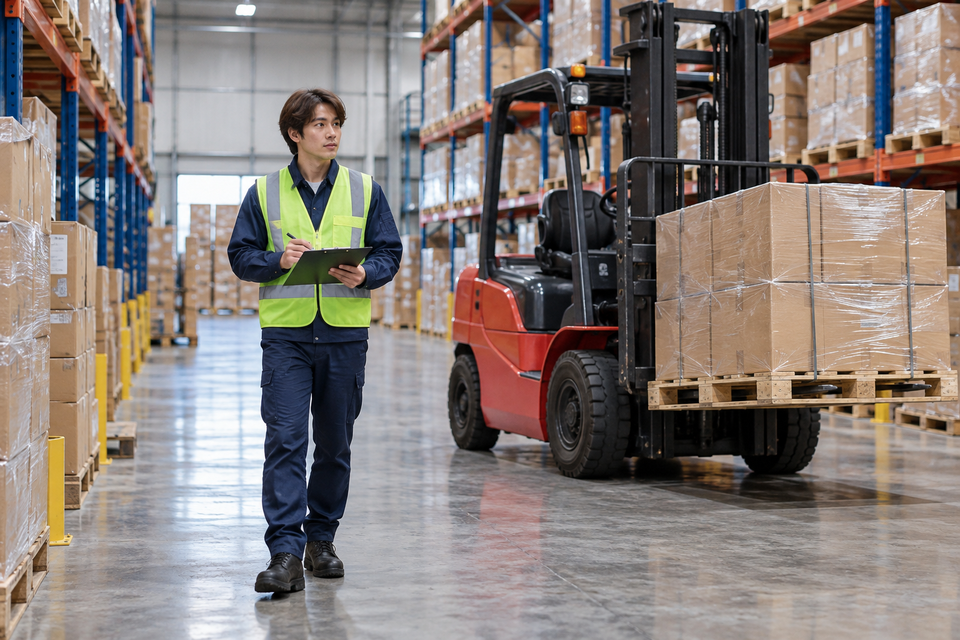

In [4]:
image = Image.open(DEMO_IMAGE_PATH).convert("RGB")
print("Image size:", image.size)
display(image)

## 4. デモ A：画像だけから同時に4種類の判定

画像には倉庫作業員・フォークリフトが描かれています。
- `noul` の出力 `noul` は **Yes の確率 (0～1)**。
- `choice` は選択された名前と選択肢ごとの確率。
- `score` は**0始まりの期待レベル**（例：0～3 の間の数値）。

※この画像は生成画像です。リスク判定は主観的な指標の試験であり、実際の保安判断には使わないでください。

In [5]:
questions = {
    "person_visible": {
        "type": "noul",
        "instructions": "Is at least one human worker visible in the image?",
    },
    "hard_hat_worn": {
        "type": "noul",
        "instructions": "Is the visible worker wearing a protective hard hat on their head?",
    },
    "vehicle_type": {
        "type": "choice",
        "instructions": "Which type of vehicle is most clearly visible?",
        "criteria": {
            "forklift": "A forklift used for moving palletized goods",
            "truck": "A cargo truck",
            "car": "A passenger car",
            "none": "No vehicle is visible",
        },
    },
    "safety_attention": {
        "type": "score",
        "instructions": "How much safety attention does this warehouse scene appear to need, considering visible PPE and proximity to machinery?",
        "criteria": [
            "0: No apparent issue, low attention needed",
            "1: Minor issue, routine awareness needed",
            "2: Potential concern, supervisor review recommended",
            "3: Serious apparent hazard, urgent safety review recommended",
        ],
    },
}

with torch.inference_mode():
    result = model.system_one(None, questions, images=[image])
print(json.dumps(result, indent=2, ensure_ascii=False))

tokenizer_config.json:   0%|          | 0.00/507 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.9MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/5.44k [00:00<?, ?B/s]

processor_config.json:   0%|          | 0.00/824 [00:00<?, ?B/s]

{
  "answers": {
    "person_visible": {
      "type": "noul",
      "noul": 0.992767236196521
    },
    "hard_hat_worn": {
      "type": "noul",
      "noul": 0.037892426629607394
    },
    "vehicle_type": {
      "type": "choice",
      "choice": "forklift",
      "confidence": 0.9844809695587076,
      "probabilities": {
        "forklift": 0.9844809695587076,
        "truck": 0.00558586649793922,
        "car": 0.0037501733584551665,
        "none": 0.00618299058489797
      }
    },
    "safety_attention": {
      "type": "score",
      "score": 1.5118060597136633,
      "confidence": 0.3949458894335355,
      "probabilities": {
        "0": 0.13023933115253203,
        "1": 0.3949458894335355,
        "2": 0.30758416796166993,
        "3": 0.16723061145226267
      },
      "legend": {
        "0": "0: No apparent issue, low attention needed",
        "1": "1: Minor issue, routine awareness needed",
        "2": "2: Potential concern, supervisor review recommended",
        "3"

## 5. 推論結果を読みやすく表示・可視化

,question,type,result,value
0,person_visible,noul,YES,0.992767
1,hard_hat_worn,noul,NO,0.037892
2,vehicle_type,choice,forklift,0.984481
3,safety_attention,score,expected score: 1.51,0.394946


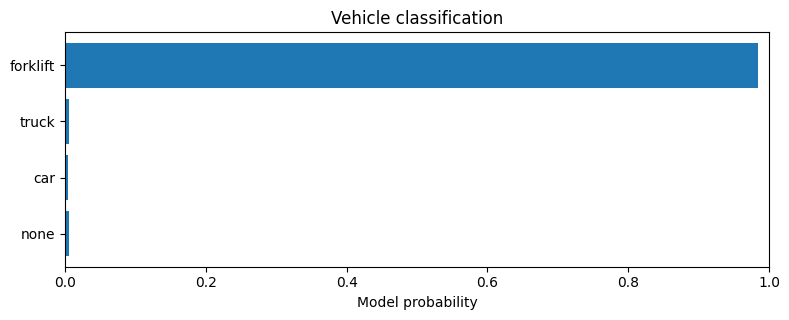

Usage: {'input_tokens': 1981, 'output_tokens': 0}
※ Confidence/probability は任意の現場で精度を保証するものではありません。


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

def summarize(result):
    rows = []
    for name, a in result["answers"].items():
        kind = a["type"]
        if kind == "noul":
            p = float(a["noul"])
            rows.append({"question": name, "type": kind, "result": "YES" if p >= .5 else "NO", "value": p})
        elif kind == "choice":
            rows.append({"question": name, "type": kind, "result": a["choice"], "value": a["confidence"]})
        else:
            rows.append({"question": name, "type": kind, "result": f"expected score: {a['score']:.2f}", "value": a["confidence"]})
    return pd.DataFrame(rows)

display(summarize(result))

vehicle = result["answers"]["vehicle_type"]["probabilities"]
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.barh(list(vehicle.keys()), list(vehicle.values()))
ax.set_xlabel("Model probability")
ax.set_xlim(0, 1)
ax.set_title("Vehicle classification")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("Usage:", result["usage"])
print("※ Confidence/probability は任意の現場で精度を保証するものではありません。")

## 6. デモ B：同じ写真 + 作業ルール（マルチモーダル）

In [7]:
site_policy = {
    "location": "Warehouse storage aisle",
    "rule": "Workers in the forklift operating area must wear both high-visibility vests and hard hats.",
    "purpose": "Review whether the photo appears to violate this PPE rule.",
}

rule_questions = {
    "ppe_violation": {
        "type": "noul",
        "instructions": "Based on the photo and the site's written rule, does the visible worker appear to violate the required PPE rule?",
    },
    "review_action": {
        "type": "choice",
        "instructions": "Which follow-up action is most appropriate based only on the visual evidence and written rule?",
        "criteria": {
            "no_action": "No apparent PPE problem; no review necessary",
            "manual_check": "Request a human supervisor to verify PPE compliance",
            "emergency": "Call emergency responders for a visible medical emergency",
        },
    },
}
with torch.inference_mode():
    rule_result = model.system_one(site_policy, rule_questions, images=[image])
print(json.dumps(rule_result, indent=2, ensure_ascii=False))

{
  "answers": {
    "ppe_violation": {
      "type": "noul",
      "noul": 0.5078118642792044
    },
    "review_action": {
      "type": "choice",
      "choice": "no_action",
      "confidence": 0.9248721331664899,
      "probabilities": {
        "no_action": 0.9248721331664899,
        "manual_check": 0.0713184809392341,
        "emergency": 0.0038093858942759586
      }
    }
  },
  "usage": {
    "input_tokens": 1955,
    "output_tokens": 0
  }
}


## 7. デモ C：文章だけの問い合わせ振り分け（一括推論）

In [8]:
team_question = {
    "team": {
        "type": "choice",
        "instructions": "Which customer support team should handle this message?",
        "criteria": {
            "billing": "Payments, invoices, refunds, or double billing",
            "technical": "Application errors, crashes, or technical failures",
            "fraud": "Suspected account takeover or unauthorised financial activity",
        },
    }
}
tickets = [
    "I was charged twice for my subscription. Please refund the extra charge.",
    "The mobile app closes immediately when I open the settings screen.",
    "A payment I did not authorize appeared on my account. I think someone stole my credentials.",
]

requests = [(t, team_question) for t in tickets]
with torch.inference_mode():
    batch_results = model.system_one_batch(requests)

for ticket, prediction in zip(tickets, batch_results):
    a = prediction["answers"]["team"]
    print(f"Message: {ticket}")
    print(f"  -> team={a['choice']}  confidence={a['confidence']:.3f}")
    print(f"  -> probabilities={a['probabilities']}")

Message: I was charged twice for my subscription. Please refund the extra charge.
  -> team=billing  confidence=0.988
  -> probabilities={'billing': 0.9882625415776118, 'technical': 0.006711086717507953, 'fraud': 0.005026371704880301}
Message: The mobile app closes immediately when I open the settings screen.
  -> team=technical  confidence=0.988
  -> probabilities={'billing': 0.005876333444630338, 'technical': 0.9882473331107394, 'fraud': 0.005876333444630338}
Message: A payment I did not authorize appeared on my account. I think someone stole my credentials.
  -> team=fraud  confidence=0.975
  -> probabilities={'billing': 0.020068334192605803, 'technical': 0.0054013188730168875, 'fraud': 0.9745303469343773}


## 8. 実測レイテンシ（モデルロード時間を含まない）

In [9]:
# 初回呼び出しでの初期化/ウォームアップの影響を分けて測定します。
N_WARMUP = 2
N_RUNS = 5
sync = torch.cuda.synchronize

with torch.inference_mode():
    for _ in range(N_WARMUP):
        model.system_one(None, questions, images=[image])
    sync()
    times = []
    for _ in range(N_RUNS):
        sync()
        start = time.perf_counter()
        model.system_one(None, questions, images=[image])
        sync()
        times.append(1000 * (time.perf_counter() - start))

print(f"GPU={torch.cuda.get_device_name(0)}")
print(f"4 questions + one PNG / median={statistics.median(times):.1f} ms, min={min(times):.1f} ms, max={max(times):.1f} ms")
print("※ 計測は Colab の実環境・GPU・混雑状況に依存。公式ベンチマークと単純比較しないでください。")

GPU=Tesla T4
4 questions + one PNG / median=1048.1 ms, min=1040.8 ms, max=1067.6 ms
※ 計測は Colab の実環境・GPU・混雑状況に依存。公式ベンチマークと単純比較しないでください。


## 9. 任意：自分のPNG/JPEGをアップロードして再判定

In [ ]:
# このセルはオプションです。必要なときだけ実行してください。
from google.colab import files
uploaded = files.upload()
if uploaded:
    path = next(iter(uploaded))
    own_image = Image.open(path).convert("RGB")
    own_image.thumbnail((1024, 1024))
    display(own_image)
    with torch.inference_mode():
        own_result = model.system_one(None, questions, images=[own_image])
    print(json.dumps(own_result, indent=2, ensure_ascii=False))

## 結果の見方 / 実験の拡張

- **Yes/No**：`noul` は `P(Yes)`。例えば 0.9 なら Yes 側のスコアが高い。
- **選択分類**：`choice`, `confidence`, `probabilities`。すべての選択肢のスコアを比較できる。
- **段階評価**：`score` は 0～3 など **順序カテゴリの期待値**。`confidence` は最頻カテゴリの確率。
- **生成ではなく選択**：`usage.output_tokens` が 0 でも forward 計算は実行されています。
- **品質検証**：照明、人物と機械の距離、ヘルメットの有無を変えた画像で再試験すると違いが見えます。

### FAQ
**CUDA out of memory**：他のノートブック/モデルを終了し、ランタイムを再起動。利用可能なら L4/A100 へ変更。画像を 512～768 px 程度に縮小し、同時質問数を減らしてください。**float16/bfloat16**：T4 は通常 FP16、L4/A100 は BF16 を選択。**`transformers` の import エラー**：Colab のランタイムを再起動して先頭から再実行。

公式： [モデルカード](https://huggingface.co/LiquidAI/d1-3B) ／ [モデル作者の API 実装](https://huggingface.co/LiquidAI/d1-3B/blob/main/api.py)。